# SleepSync – Sleep & Mood Relationship Analyzer

In [1]:
import pandas as pd
import numpy as np

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
demographic = pd.read_csv("dataset/demographic.csv")
phq = pd.read_csv("dataset/phq9.csv")
gad = pd.read_csv("dataset/gad7.csv")
isi = pd.read_csv("dataset/isi.csv")
pss = pd.read_csv("dataset/pss.csv")

In [4]:
print("Demographic shape:", demographic.shape)
print("PHQ-9 shape:", phq.shape)
print("GAD-7 shape:", gad.shape)
print("ISI shape:", isi.shape)
print("PSS shape:", pss.shape)

Demographic shape: (24292, 6)
PHQ-9 shape: (24292, 20)
GAD-7 shape: (24292, 16)
ISI shape: (24292, 16)
PSS shape: (24292, 30)


In [5]:
print(demographic.head())

   export_id  gender   age                edu         smoke  \
0      61793  female  19.0  bachelor's degree  never smokes   
1      61809  female  18.0  bachelor's degree  never smokes   
2      61737    male  40.0    master's degree  never smokes   
3      61738  female  23.0  bachelor's degree  never smokes   
4      61739  female  21.0  bachelor's degree  never smokes   

                                         drink  
0                                 never drinks  
1                                 never drinks  
2  drinks occasionally (less than once a week)  
3                                 never drinks  
4                                 never drinks  


In [6]:
print(phq.head())

   export_id  score  question1  time1  question2  time2  question3  time3  \
0      61793      0          0   2.47          0   1.23          0   1.12   
1      61809      0          0   8.22          0   7.08          0   1.24   
2      61737      0          0   1.88          0   1.65          0   1.00   
3      61738      0          0   1.74          0   2.02          0   2.26   
4      61739      2          1   5.54          0   2.57          0   1.30   

   question4  time4  question5  time5  question6  time6  question7  time7  \
0          0   1.73          0   4.74          0   1.32          0   0.16   
1          0   1.08          0   1.77          0   1.26          0   1.05   
2          0   1.18          0   0.81          0   1.29          0   4.17   
3          0   0.76          0   0.59          0   0.62          0   0.54   
4          0   2.19          0   1.08          1   3.33          0   3.13   

   question8  time8  question9  time9  
0          0  12.99          0   4

In [7]:
print("PHQ-9 columns:", phq.columns.tolist())

PHQ-9 columns: ['export_id', 'score', 'question1', 'time1', 'question2', 'time2', 'question3', 'time3', 'question4', 'time4', 'question5', 'time5', 'question6', 'time6', 'question7', 'time7', 'question8', 'time8', 'question9', 'time9']


In [8]:
phq_items = phq[["export_id"] + ["question" + str(i) for i in range(1, 10)]].copy()
phq_items.columns = ["export_id"] + ["phq_" + str(i) for i in range(1, 10)]
phq_items["phq_total"] = phq["score"]

In [9]:
gad_items = gad[["export_id"] + ["question" + str(i) for i in range(1, 8)]].copy()
gad_items.columns = ["export_id"] + ["gad_" + str(i) for i in range(1, 8)]
gad_items["gad_total"] = gad["score"]

In [10]:
isi_items = isi[["export_id"] + ["question" + str(i) for i in range(1, 8)]].copy()
isi_items.columns = ["export_id"] + ["isi_" + str(i) for i in range(1, 8)]
isi_items["isi_total"] = isi["score"]

In [11]:
pss_total = pss[["export_id", "score"]].copy()
pss_total.columns = ["export_id", "pss_total"]

In [12]:
df = demographic.merge(phq_items, on="export_id")
print("After PHQ-9 merge:", df.shape)

After PHQ-9 merge: (24292, 16)


In [13]:
df = df.merge(gad_items, on="export_id")
print("After GAD-7 merge:", df.shape)

After GAD-7 merge: (24292, 24)


In [14]:
df = df.merge(isi_items, on="export_id")
print("After ISI merge:", df.shape)

After ISI merge: (24292, 32)


In [15]:
df = df.merge(pss_total, on="export_id")
print("After PSS merge:", df.shape)

After PSS merge: (24292, 33)


In [16]:
print("Merged dataset shape:", df.shape)
print(df.columns.tolist())

Merged dataset shape: (24292, 33)
['export_id', 'gender', 'age', 'edu', 'smoke', 'drink', 'phq_1', 'phq_2', 'phq_3', 'phq_4', 'phq_5', 'phq_6', 'phq_7', 'phq_8', 'phq_9', 'phq_total', 'gad_1', 'gad_2', 'gad_3', 'gad_4', 'gad_5', 'gad_6', 'gad_7', 'gad_total', 'isi_1', 'isi_2', 'isi_3', 'isi_4', 'isi_5', 'isi_6', 'isi_7', 'isi_total', 'pss_total']


In [17]:
df.head()

,export_id,gender,age,edu,smoke,drink,phq_1,phq_2,phq_3,phq_4,...,gad_total,isi_1,isi_2,isi_3,isi_4,isi_5,isi_6,isi_7,isi_total,pss_total
0,61793,female,19.0,bachelor's degree,never smokes,never drinks,0,0,0,0,...,0,0,0,0,0,0,0,0,0,2
1,61809,female,18.0,bachelor's degree,never smokes,never drinks,0,0,0,0,...,0,0,0,0,0,0,0,0,0,21
2,61737,male,40.0,master's degree,never smokes,drinks occasionally (less than once a week),0,0,0,0,...,0,0,0,0,0,0,0,0,0,4
3,61738,female,23.0,bachelor's degree,never smokes,never drinks,0,0,0,0,...,0,0,0,0,0,0,0,0,0,28
4,61739,female,21.0,bachelor's degree,never smokes,never drinks,1,0,0,0,...,0,0,0,0,0,0,0,0,0,16


In [18]:
print("Dataset shape:", df.shape)
print(df.head())

Dataset shape: (24292, 33)
   export_id  gender   age                edu         smoke  \
0      61793  female  19.0  bachelor's degree  never smokes   
1      61809  female  18.0  bachelor's degree  never smokes   
2      61737    male  40.0    master's degree  never smokes   
3      61738  female  23.0  bachelor's degree  never smokes   
4      61739  female  21.0  bachelor's degree  never smokes   

                                         drink  phq_1  phq_2  phq_3  phq_4  \
0                                 never drinks      0      0      0      0   
1                                 never drinks      0      0      0      0   
2  drinks occasionally (less than once a week)      0      0      0      0   
3                                 never drinks      0      0      0      0   
4                                 never drinks      1      0      0      0   

   ...  gad_total  isi_1  isi_2  isi_3  isi_4  isi_5  isi_6  isi_7  isi_total  \
0  ...          0      0      0      0      

In [19]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 24292 entries, 0 to 24291
Data columns (total 33 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   export_id  24292 non-null  int64  
 1   gender     24292 non-null  str    
 2   age        24292 non-null  float64
 3   edu        24292 non-null  str    
 4   smoke      24292 non-null  str    
 5   drink      24292 non-null  str    
 6   phq_1      24292 non-null  int64  
 7   phq_2      24292 non-null  int64  
 8   phq_3      24292 non-null  int64  
 9   phq_4      24292 non-null  int64  
 10  phq_5      24292 non-null  int64  
 11  phq_6      24292 non-null  int64  
 12  phq_7      24292 non-null  int64  
 13  phq_8      24292 non-null  int64  
 14  phq_9      24292 non-null  int64  
 15  phq_total  24292 non-null  int64  
 16  gad_1      24292 non-null  int64  
 17  gad_2      24292 non-null  int64  
 18  gad_3      24292 non-null  int64  
 19  gad_4      24292 non-null  int64  
 20  gad_5      24292 

In [20]:
df.describe()

,export_id,age,phq_1,phq_2,phq_3,phq_4,phq_5,phq_6,phq_7,phq_8,...,gad_total,isi_1,isi_2,isi_3,isi_4,isi_5,isi_6,isi_7,isi_total,pss_total
count,24292.000000,24292.000000,24292.000000,24292.000000,24292.000000,24292.000000,24292.000000,24292.000000,24292.000000,24292.000000,...,24292.000000,24292.000000,24292.000000,24292.000000,24292.000000,24292.000000,24292.000000,24292.000000,24292.000000,24292.000000
mean,73894.702536,20.655730,0.536720,0.464474,0.442409,0.494443,0.339865,0.387494,0.350074,0.164499,...,1.914128,0.396139,0.237980,0.234892,0.675078,0.536926,0.312407,0.384159,2.777581,19.991191
std,7028.103647,2.408713,0.641435,0.577255,0.672949,0.630952,0.594323,0.605558,0.610145,0.433398,...,2.919028,0.700599,0.575502,0.566361,0.809468,0.686918,0.609171,0.642806,3.437386,8.320719
min,61737.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,67809.750000,19.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000
50%,73885.500000,20.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,20.000000
75%,79977.250000,22.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,...,3.000000,1.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,4.000000,27.000000
max,101310.000000,99.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,...,21.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,28.000000,56.000000


In [21]:
print(df.isnull().sum().sum())

0


In [22]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate student ids:", df["export_id"].duplicated().sum())

Duplicate rows: 0
Duplicate student ids: 0


In [23]:
for col in ["gender", "edu", "smoke", "drink"]:
    print("\n", col)
    print(df[col].value_counts())


 gender
gender
female    15545
male       8747
Name: count, dtype: int64

 edu
edu
bachelor's degree    22290
associate degree      1285
master's degree        675
doctorate degree        42
Name: count, dtype: int64

 smoke
smoke
never smokes                                                              22513
occasional smoker (cumulative smoking <10 packs)                           1044
current smoker (cumulative smoking >10 packs)                               542
former smoker (cumulative smoking >10 packs), but not in the past year      193
Name: count, dtype: int64

 drink
drink
never drinks                                                           16404
drinks occasionally (less than once a week)                             7359
drank in the past (more than once a week), but not in the past year      284
current regular drinker (more than once a week)                          245
Name: count, dtype: int64


In [24]:
print("Minimum age:", df["age"].min())
print("Maximum age:", df["age"].max())
print("Students with age below 16:", (df["age"] < 16).sum())
print("Students with age above 40:", (df["age"] > 40).sum())

Minimum age: 1.0
Maximum age: 99.0
Students with age below 16: 22
Students with age above 40: 18


In [25]:
phq_cols = ["phq_" + str(i) for i in range(1, 10)]
gad_cols = ["gad_" + str(i) for i in range(1, 8)]
isi_cols = ["isi_" + str(i) for i in range(1, 8)]

In [26]:
print("PHQ-9 total matches item sum:", (df[phq_cols].sum(axis=1) == df["phq_total"]).mean())
print("GAD-7 total matches item sum:", (df[gad_cols].sum(axis=1) == df["gad_total"]).mean())
print("ISI total matches item sum:", (df[isi_cols].sum(axis=1) == df["isi_total"]).mean())

PHQ-9 total matches item sum: 1.0
GAD-7 total matches item sum: 1.0
ISI total matches item sum: 1.0


In [27]:
print("PHQ-9 item range:", df[phq_cols].min().min(), "to", df[phq_cols].max().max())
print("GAD-7 item range:", df[gad_cols].min().min(), "to", df[gad_cols].max().max())
print("ISI item range:", df[isi_cols].min().min(), "to", df[isi_cols].max().max())

PHQ-9 item range: 0 to 3
GAD-7 item range: 0 to 3
ISI item range: 0 to 4


In [28]:
print("PHQ-9 total range:", df["phq_total"].min(), "to", df["phq_total"].max(), "(possible 0 to 27)")
print("GAD-7 total range:", df["gad_total"].min(), "to", df["gad_total"].max(), "(possible 0 to 21)")
print("ISI total range:", df["isi_total"].min(), "to", df["isi_total"].max(), "(possible 0 to 28)")
print("PSS total range:", df["pss_total"].min(), "to", df["pss_total"].max(), "(possible 0 to 56)")

PHQ-9 total range: 0 to 27 (possible 0 to 27)
GAD-7 total range: 0 to 21 (possible 0 to 21)
ISI total range: 0 to 28 (possible 0 to 28)
PSS total range: 0 to 56 (possible 0 to 56)


In [29]:
print("Correlation between PHQ-9 question 3 and ISI total:", round(df["phq_3"].corr(df["isi_total"]), 2))

Correlation between PHQ-9 question 3 and ISI total: 0.63


In [30]:
print("Dataset shape:", df.shape)

Dataset shape: (24292, 33)


In [31]:
df.columns = df.columns.str.strip()

In [32]:
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip().str.lower()

C:\Users\Bhoomi\AppData\Local\Temp\ipykernel_13060\1452289883.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include="object").columns:


In [33]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate student ids:", df["export_id"].duplicated().sum())

Duplicate rows: 0
Duplicate student ids: 0


In [34]:
df = df.drop_duplicates()
df = df.drop_duplicates(subset="export_id")

In [35]:
print("Dataset shape after removing duplicates:", df.shape)

Dataset shape after removing duplicates: (24292, 33)


In [36]:
print(df.isnull().sum().sum())

0


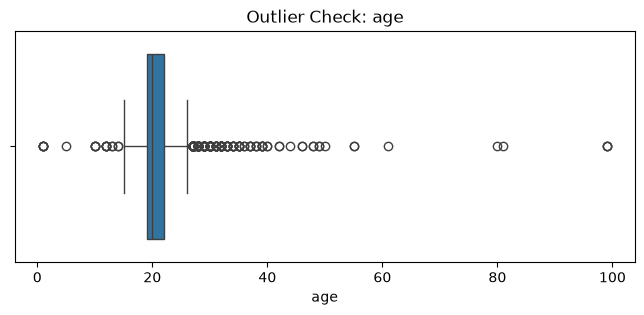

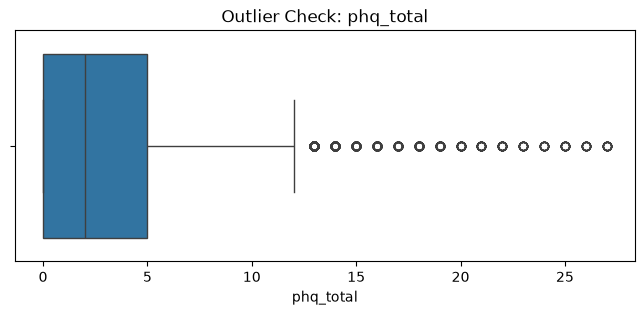

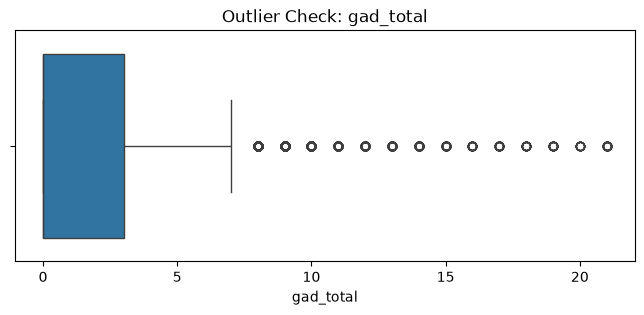

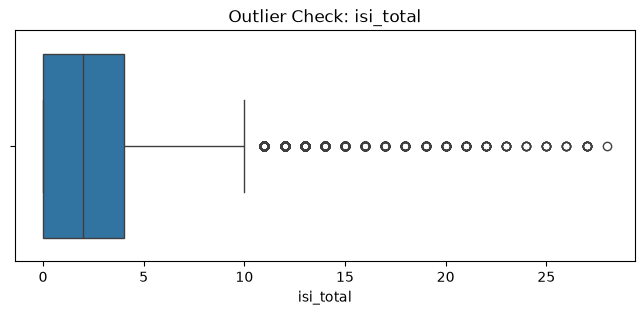

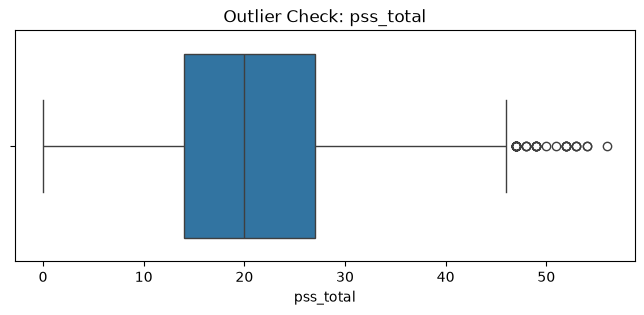

In [37]:
num_cols = ["age", "phq_total", "gad_total", "isi_total", "pss_total"]
for col in num_cols:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=df[col])
    plt.title("Outlier Check: " + col)
    plt.show()

In [38]:
outlier_results = []
for col in num_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = ((df[col] < lower) | (df[col] > upper)).sum()
    outlier_results.append({
        "Column": col,
        "Lower Bound": round(lower, 2),
        "Upper Bound": round(upper, 2),
        "Flagged Values": int(count)
    })
outlier_df = pd.DataFrame(outlier_results)
print(outlier_df.to_string(index=False))

   Column  Lower Bound  Upper Bound  Flagged Values
      age         14.5         26.5             299
phq_total         -7.5         12.5             605
gad_total         -4.5          7.5            1004
isi_total         -6.0         10.0             939
pss_total         -5.5         46.5              40


In [39]:
print("Minimum age:", df["age"].min())
print("Maximum age:", df["age"].max())

Minimum age: 1.0
Maximum age: 99.0


In [40]:
invalid_age = (df["age"] < 16) | (df["age"] > 40)
print("Rows with invalid age:", invalid_age.sum())

Rows with invalid age: 40


In [41]:
df = df[~invalid_age].copy()
print("Dataset shape after age filter:", df.shape)

Dataset shape after age filter: (24252, 33)


In [42]:
print("Minimum age:", df["age"].min())
print("Maximum age:", df["age"].max())

Minimum age: 16.0
Maximum age: 40.0


In [43]:
phq_no_sleep = ["phq_" + str(i) for i in range(1, 10) if i != 3]
print(phq_no_sleep)

['phq_1', 'phq_2', 'phq_4', 'phq_5', 'phq_6', 'phq_7', 'phq_8', 'phq_9']


In [44]:
df["mood_score"] = df[phq_no_sleep].sum(axis=1)
print(df["mood_score"].describe())

count    24252.000000
mean         2.820015
std          3.238282
min          0.000000
25%          0.000000
50%          2.000000
75%          5.000000
max         24.000000
Name: mood_score, dtype: float64


In [45]:
df["anxiety_score"] = df["gad_total"]

In [46]:
df["female"] = (df["gender"] == "female").astype(int)

The target low_mood is 1 when the mood score is 5 or more (mild or higher mood symptoms on the PHQ-9 scale). The usual PHQ-9 cutoff of 10 would flag only about 4% of students, which is too few for a model to learn from.

In [47]:
for t in [5, 8, 10]:
    print("Mood score >=", t, ":", round((df["mood_score"] >= t).mean() * 100, 2), "% of students")

Mood score >= 5 : 25.61 % of students
Mood score >= 8 : 7.87 % of students
Mood score >= 10 : 3.69 % of students


In [48]:
df["low_mood"] = (df["mood_score"] >= 5).astype(int)
print(df["low_mood"].value_counts())
print(df["low_mood"].value_counts(normalize=True).round(3))

low_mood
0    18040
1     6212
Name: count, dtype: int64
low_mood
0    0.744
1    0.256
Name: proportion, dtype: float64


In [49]:
df["sleep_group"] = pd.cut(
    df["isi_total"],
    bins=[-1, 7, 14, 28],
    labels=["No problem", "Mild", "Moderate or severe"]
)
print(df["sleep_group"].value_counts())

sleep_group
No problem            22058
Mild                   1916
Moderate or severe      278
Name: count, dtype: int64


In [50]:
print("Dataset shape:", df.shape)
print(df.isnull().sum().sum())

Dataset shape: (24252, 38)
0


In [51]:
df.to_csv("cleaned_data.csv", index=False)
print("cleaned_data.csv saved")

cleaned_data.csv saved


In [52]:
print("Dataset shape:", df.shape)

Dataset shape: (24252, 38)


low_mood
0    0.744
1    0.256
Name: proportion, dtype: float64


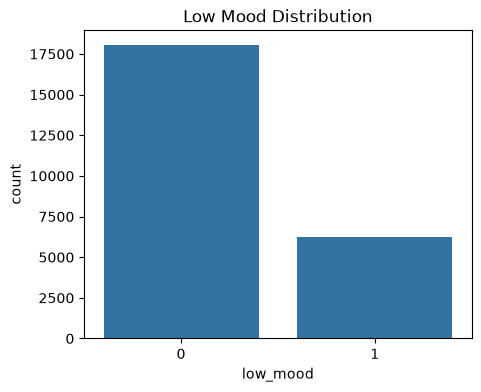

In [53]:
print(df["low_mood"].value_counts(normalize=True).round(3))
plt.figure(figsize=(5, 4))
sns.countplot(x="low_mood", data=df)
plt.title("Low Mood Distribution")
plt.show()

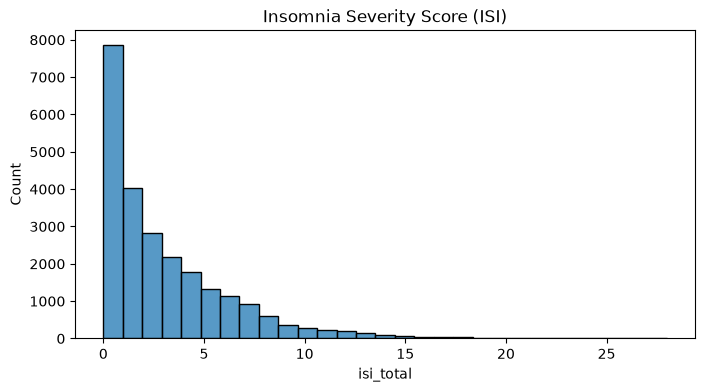

In [54]:
plt.figure(figsize=(8, 4))
sns.histplot(df["isi_total"], bins=29)
plt.title("Insomnia Severity Score (ISI)")
plt.show()

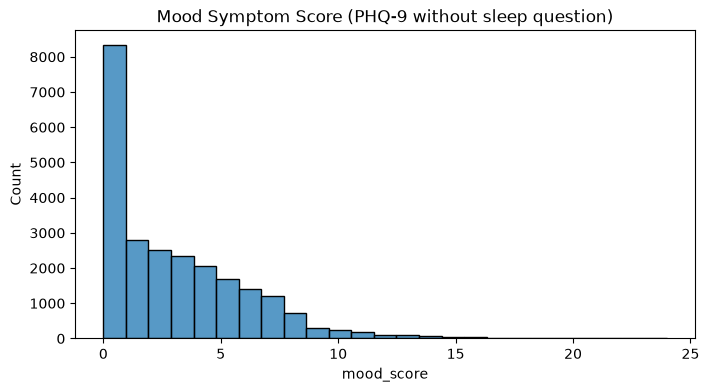

In [55]:
plt.figure(figsize=(8, 4))
sns.histplot(df["mood_score"], bins=25)
plt.title("Mood Symptom Score (PHQ-9 without sleep question)")
plt.show()

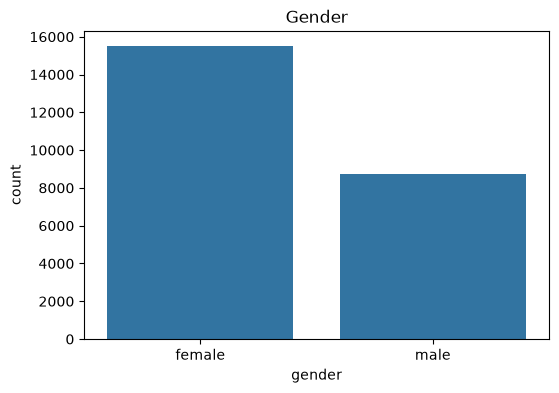

In [56]:
plt.figure(figsize=(6, 4))
sns.countplot(x="gender", data=df)
plt.title("Gender")
plt.show()

In [57]:
sleep_summary = df.groupby("sleep_group", observed=True)[["mood_score", "anxiety_score", "pss_total"]].mean().round(2)
sleep_summary["students"] = df["sleep_group"].value_counts()
print(sleep_summary)

                    mood_score  anxiety_score  pss_total  students
sleep_group                                                       
No problem                2.37           1.50      19.24     22058
Mild                      6.86           5.56      26.99      1916
Moderate or severe       10.61           9.30      30.82       278


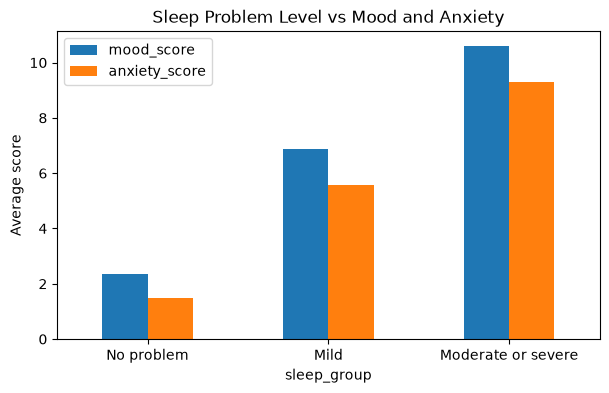

In [58]:
sleep_summary[["mood_score", "anxiety_score"]].plot(kind="bar", figsize=(7, 4))
plt.title("Sleep Problem Level vs Mood and Anxiety")
plt.ylabel("Average score")
plt.xticks(rotation=0)
plt.show()

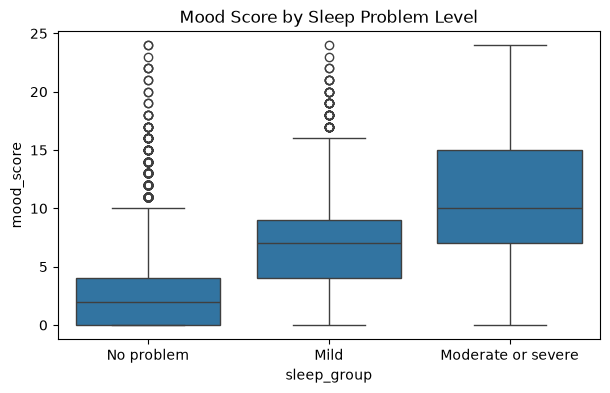

In [59]:
plt.figure(figsize=(7, 4))
sns.boxplot(x="sleep_group", y="mood_score", data=df)
plt.title("Mood Score by Sleep Problem Level")
plt.show()

In [60]:
print(pd.crosstab(df["sleep_group"], df["low_mood"], normalize="index").round(3))

low_mood                0      1
sleep_group                     
No problem          0.793  0.207
Mild                0.262  0.738
Moderate or severe  0.147  0.853


In [61]:
for col in ["gender", "smoke", "drink"]:
    print("\n", col)
    print(pd.crosstab(df[col], df["low_mood"], normalize="index").round(3))


 gender
low_mood      0      1
gender                
female    0.738  0.262
male      0.755  0.245

 smoke
low_mood                                                0      1
smoke                                                           
current smoker (cumulative smoking >10 packs)       0.627  0.373
former smoker (cumulative smoking >10 packs), b...  0.624  0.376
never smokes                                        0.752  0.248
occasional smoker (cumulative smoking <10 packs)    0.647  0.353

 drink
low_mood                                                0      1
drink                                                           
current regular drinker (more than once a week)     0.548  0.452
drank in the past (more than once a week), but ...  0.604  0.396
drinks occasionally (less than once a week)         0.682  0.318
never drinks                                        0.777  0.223


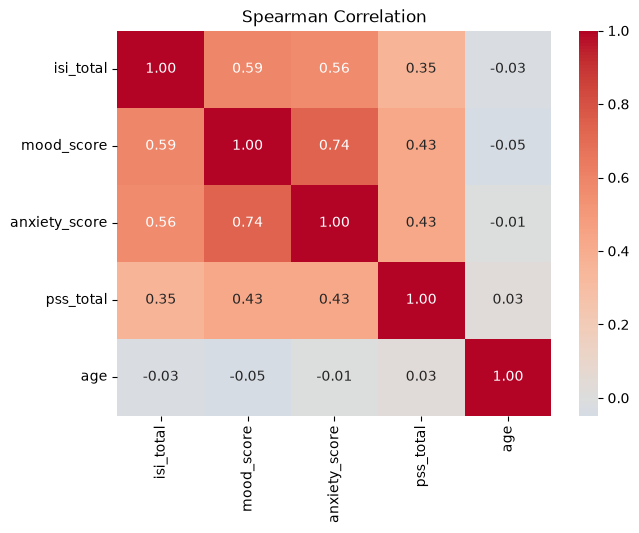

In [62]:
corr_cols = ["isi_total", "mood_score", "anxiety_score", "pss_total", "age"]
plt.figure(figsize=(7, 5))
sns.heatmap(df[corr_cols].corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Spearman Correlation")
plt.show()

In [63]:
isi_cols = ["isi_" + str(i) for i in range(1, 8)]
print(df[isi_cols + ["mood_score"]].corr(method="spearman")["mood_score"].drop("mood_score").round(2))

isi_1    0.47
isi_2    0.41
isi_3    0.33
isi_4    0.50
isi_5    0.48
isi_6    0.30
isi_7    0.47
Name: mood_score, dtype: float64


In [64]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

In [65]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

In [66]:
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

In [67]:
isi_cols = ["isi_" + str(i) for i in range(1, 8)]
features = isi_cols + ["age", "gender", "smoke", "drink"]
print(features)

['isi_1', 'isi_2', 'isi_3', 'isi_4', 'isi_5', 'isi_6', 'isi_7', 'age', 'gender', 'smoke', 'drink']


In [68]:
X = df[features]
y = df["low_mood"]
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (24252, 11)
Target shape: (24252,)


In [69]:
num_cols = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = X.select_dtypes(include=["object"]).columns.tolist()

C:\Users\Bhoomi\AppData\Local\Temp\ipykernel_13060\1671139452.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object"]).columns.tolist()


In [70]:
print("Numerical columns:", num_cols)
print("Categorical columns:", cat_cols)

Numerical columns: ['isi_1', 'isi_2', 'isi_3', 'isi_4', 'isi_5', 'isi_6', 'isi_7', 'age']
Categorical columns: ['gender', 'smoke', 'drink']


In [71]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [72]:
print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])
print("Low mood in training set (%):", round(y_train.mean() * 100, 2))
print("Low mood in testing set (%):", round(y_test.mean() * 100, 2))

Training rows: 19401
Testing rows: 4851
Low mood in training set (%): 25.61
Low mood in testing set (%): 25.62


In [73]:
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
])

Low mood students are only about a quarter of the data, so accuracy alone can look good even for a model that never finds them. A baseline model that always predicts "not low" is added for comparison, and the other models use class_weight="balanced".

In [74]:
models = {
    "Baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        class_weight="balanced",
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=8,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}


Model: Baseline

Classification Report:
              precision    recall  f1-score   support

Not low mood       0.74      1.00      0.85      3608
    Low mood       0.00      0.00      0.00      1243

    accuracy                           0.74      4851
   macro avg       0.37      0.50      0.43      4851
weighted avg       0.55      0.74      0.63      4851



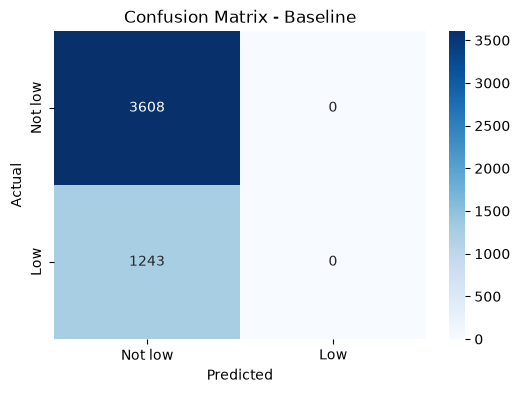


Model: Logistic Regression

Classification Report:
              precision    recall  f1-score   support

Not low mood       0.88      0.80      0.83      3608
    Low mood       0.53      0.67      0.59      1243

    accuracy                           0.76      4851
   macro avg       0.70      0.73      0.71      4851
weighted avg       0.79      0.76      0.77      4851



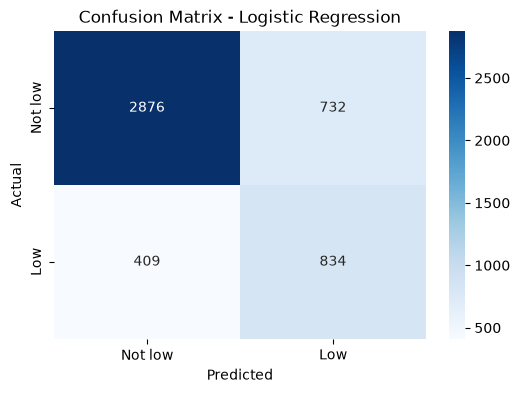


Model: Decision Tree

Classification Report:
              precision    recall  f1-score   support

Not low mood       0.88      0.75      0.81      3608
    Low mood       0.49      0.71      0.58      1243

    accuracy                           0.74      4851
   macro avg       0.69      0.73      0.69      4851
weighted avg       0.78      0.74      0.75      4851



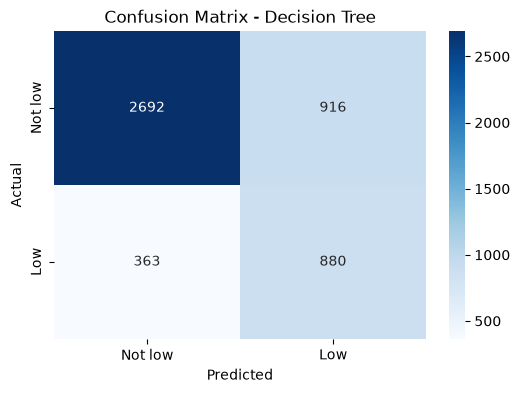


Model: Random Forest

Classification Report:
              precision    recall  f1-score   support

Not low mood       0.88      0.77      0.82      3608
    Low mood       0.51      0.69      0.59      1243

    accuracy                           0.75      4851
   macro avg       0.69      0.73      0.70      4851
weighted avg       0.78      0.75      0.76      4851



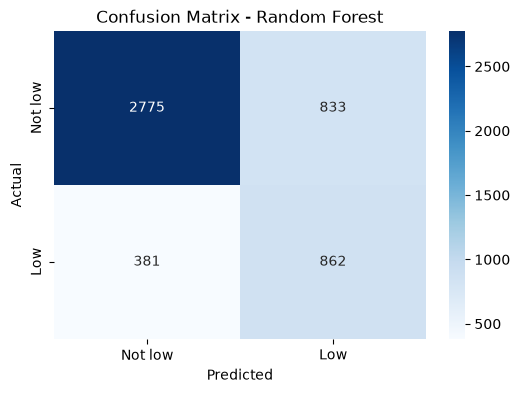

In [75]:
results = []
for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", model)
    ])
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    auc = roc_auc_score(y_test, y_prob)
    results.append({
        "Model": name,
        "Accuracy (%)": round(accuracy * 100, 2),
        "Precision (%)": round(precision * 100, 2),
        "Recall (%)": round(recall * 100, 2),
        "F1 Score (%)": round(f1 * 100, 2),
        "ROC-AUC": round(auc, 3)
    })
    print("\n", "=" * 50)
    print("Model:", name)
    print("=" * 50)
    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Not low mood", "Low mood"],
        zero_division=0
    ))
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    plt.figure(figsize=(6, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Not low", "Low"],
        yticklabels=["Not low", "Low"]
    )
    plt.title("Confusion Matrix - " + name)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

In [76]:
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="F1 Score (%)",
    ascending=False
)
print("\nFinal Model Comparison:")
print(results_df.to_string(index=False))


Final Model Comparison:
              Model  Accuracy (%)  Precision (%)  Recall (%)  F1 Score (%)  ROC-AUC
Logistic Regression         76.48          53.26       67.10         59.38    0.806
      Random Forest         74.97          50.86       69.35         58.68    0.808
      Decision Tree         73.63          49.00       70.80         57.91    0.797
           Baseline         74.38           0.00        0.00          0.00    0.500


In [82]:
best_model = results_df.iloc[0]
print("Best Model:", best_model["Model"])
print("Best F1 Score:", best_model["F1 Score (%)"], "%")
print("Best Accuracy:", best_model["Accuracy (%)"], "%")
print("Precision of best model:", best_model["Precision (%)"], "%")
print("Recall of best model:", best_model["Recall (%)"], "%")

Best Model: Logistic Regression
Best F1 Score: 59.38 %
Best Accuracy: 76.48 %
Precision of best model: 53.26 %
Recall of best model: 67.1 %
